<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex04_HW_solution_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 04: reference solution (Sarasota houses)

This reference solution was prepared with an AI assistant. It shows one correct way through the tasks, not the only one. Beyond the assignment it starts with an exploratory data analysis (Section 0), and the tasks then use the cleaned data.

Notation as in the lectures: $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}$, $h(\mathbf{X}) = m+1$, $\widehat{\boldsymbol{\beta}}$, $\widehat{\mathbf{e}}$, $s_n^2 = \mathrm{SSE}/(n-m-1)$, $\mathbf{H} = \mathbf{X}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T$, $\mathbf{M} = \mathbf{I} - \mathbf{H}$, leverages $h_{ii}$.

**Scope.** The homework uses Lectures 1–5 and Exercises 01–05. Where this solution uses a method that the course has not reached yet, it is marked **[beyond Lecture 5]** and the main answer does not depend on it.

## 0. Exploratory data analysis (beyond the assignment)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from patsy import dmatrices

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
rng = np.random.default_rng(2026)

url_houses = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/sarasota_houses_mod.csv'
houses = pd.read_csv(url_houses)
print(f'Rows: {houses.shape[0]}, columns: {houses.shape[1]}')
print('missing values:', houses.isna().sum()[lambda s_: s_ > 0].to_dict())
houses.describe().T

Rows: 1057, columns: 8
missing values: {'price': 2, 'lot_size': 9}


,count,mean,std,min,25%,50%,75%,max
price,1055.0,167687.8853,77067.8903,16858.0,112276.50,152112.00,206496.00,599701.0
living_area,1057.0,1819.4976,662.9414,672.0,1342.00,1675.00,2223.00,5228.0
bathrooms,1057.0,1.9286,0.6501,1.0,1.50,2.00,2.50,4.5
bedrooms,1057.0,3.1845,0.7405,1.0,3.00,3.00,4.00,5.0
fireplaces,1057.0,0.6244,0.5504,0.0,0.00,1.00,1.00,4.0
lot_size,1048.0,0.5700,0.7663,0.0,0.21,0.39,0.61,9.0
age,1057.0,28.0899,34.9280,0.0,6.00,18.00,34.00,247.0


- 1057 houses, 8 columns; `price` missing for 2 houses, `lot_size` for 9 (not used).
- Ranges: price 17 to 600 thousand USD, living area 672 to 5228 sq ft, age 0 to **247 years**, bedrooms 1–5, bathrooms 1–4.5 in steps of 0.5.

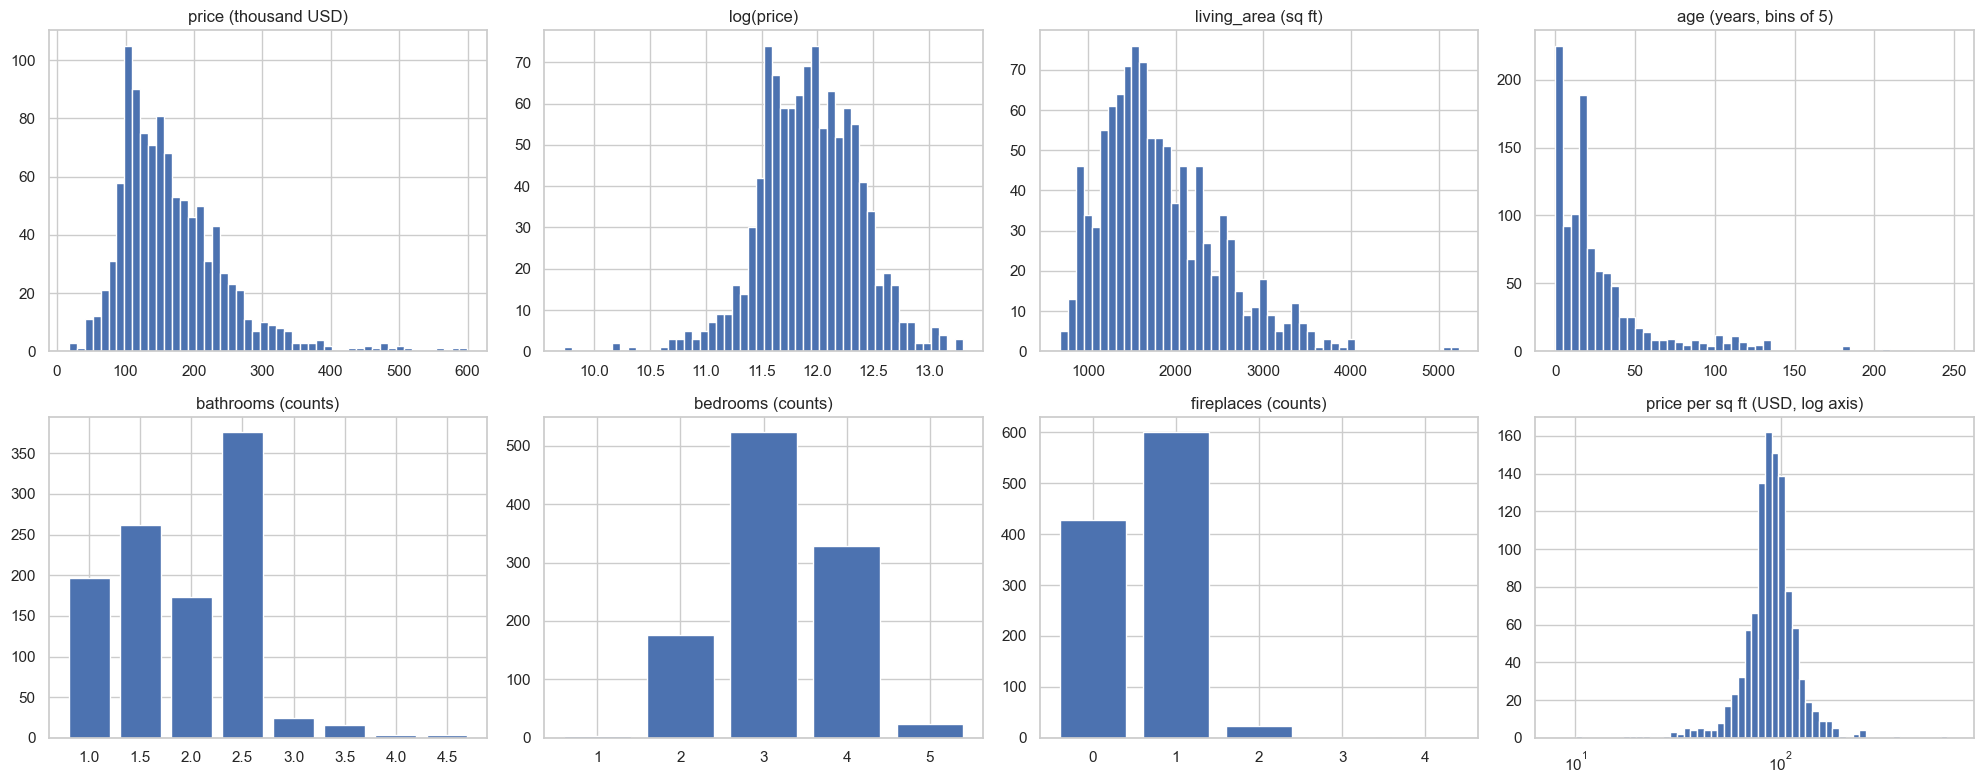

In [2]:
h = houses.dropna(subset=['price']).copy()
h['price_per_sqft'] = h['price'] / h['living_area']
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()
axes[0].hist(h['price'] / 1000, bins=50); axes[0].set_title('price (thousand USD)')
axes[1].hist(np.log(h['price']), bins=50); axes[1].set_title('log(price)')
axes[2].hist(h['living_area'], bins=50); axes[2].set_title('living_area (sq ft)')
axes[3].hist(h['age'], bins=np.arange(0, 251, 5)); axes[3].set_title('age (years, bins of 5)')
for ax, col in zip(axes[4:7], ['bathrooms', 'bedrooms', 'fireplaces']):
    vc = h[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values); ax.set_title(f'{col} (counts)')
axes[7].hist(h['price_per_sqft'], bins=np.geomspace(8, 700, 60)); axes[7].set_xscale('log')
axes[7].set_title('price per sq ft (USD, log axis)')
plt.tight_layout()
plt.show()

- **price**: right-skewed, tail up to 600 thousand; **log(price)** nearly symmetric, a few very cheap houses in the left tail.
- **living_area**: right-skewed; two houses above 5000 sq ft, the next largest about 4000.
- **age**: a spike at 0–1 years (new construction), many houses 14–20 years old, a long tail with a few houses over 150 years.
- **bathrooms, bedrooms, fireplaces**: discrete; one bedroom only 3 houses, 3 or 4 fireplaces only 3 houses: coefficients at the extremes rest on little data.
- **price per sq ft** (log axis): median about 90 USD, but from 10 to 608 USD; both tails suspicious (checks below).

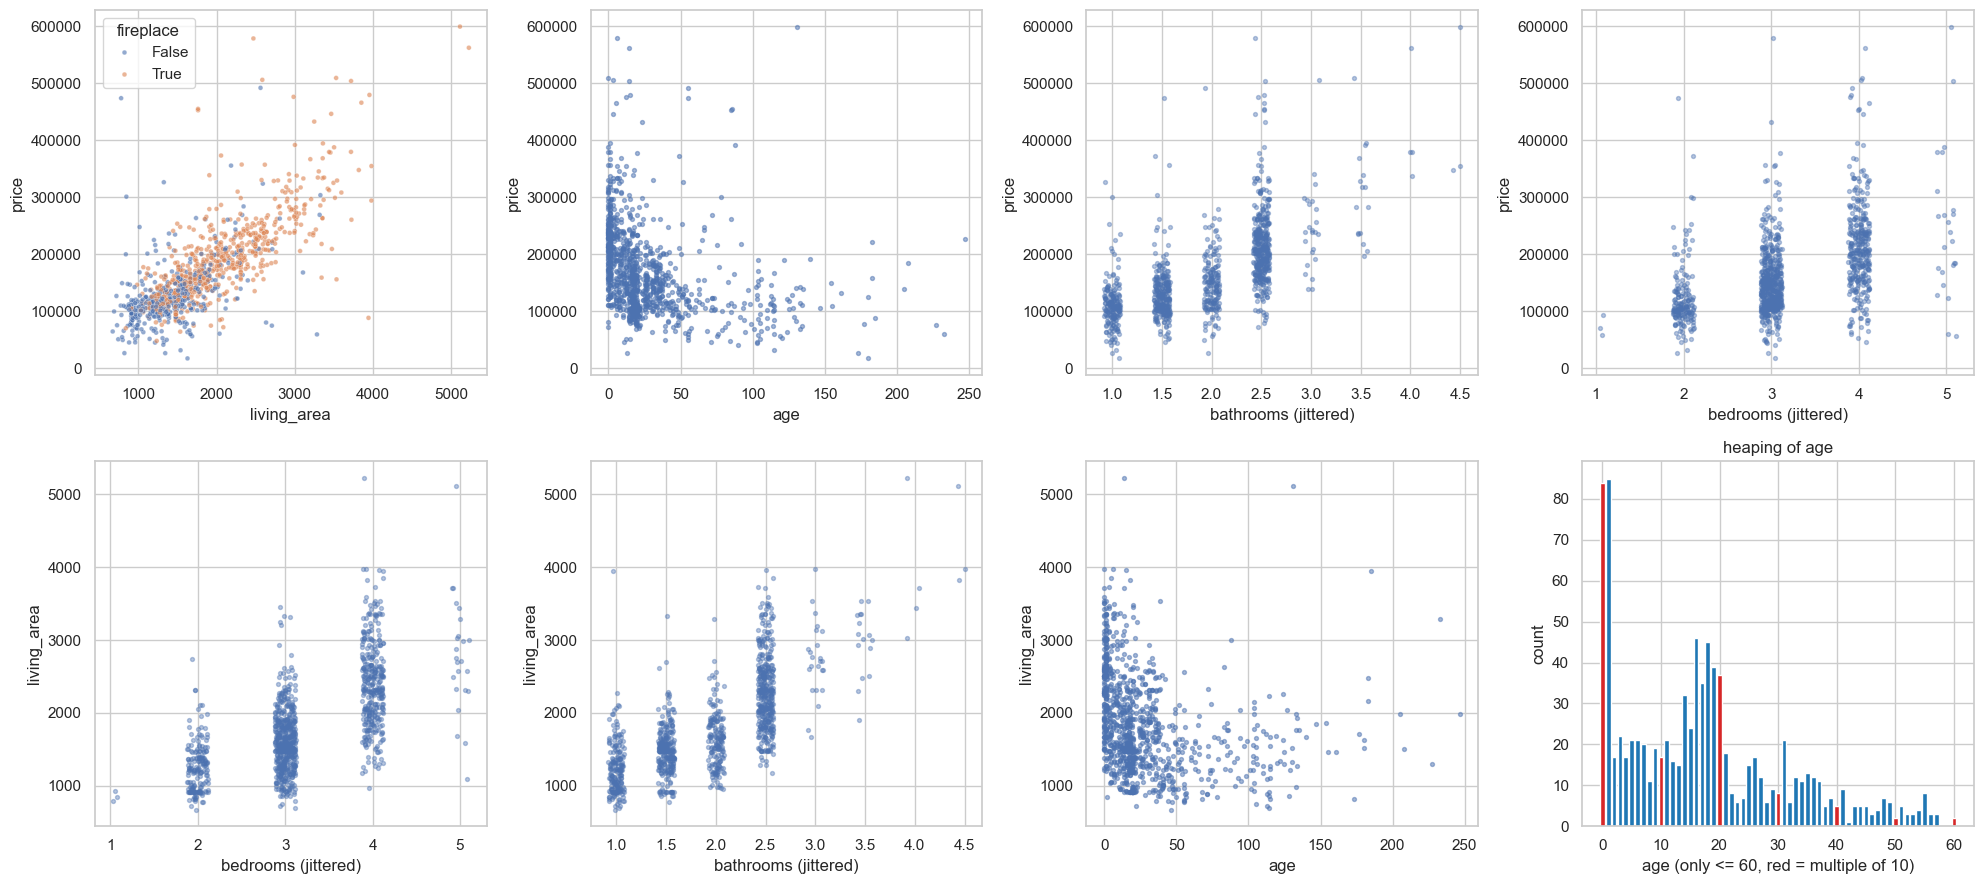

             price  living_area  bathrooms  bedrooms   age  fireplaces
price         1.00         0.76       0.65      0.46 -0.30        0.45
living_area   0.76         1.00       0.73      0.66 -0.25        0.51
bathrooms     0.65         0.73       1.00      0.51 -0.42        0.44
bedrooms      0.46         0.66       0.51      1.00 -0.06        0.28
age          -0.30        -0.25      -0.42     -0.06  1.00       -0.22
fireplaces    0.45         0.51       0.44      0.28 -0.22        1.00


In [3]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()
jit = lambda v, w: v + rng.uniform(-w, w, len(v))
sns.scatterplot(data=h, x='living_area', y='price', hue='fireplace', s=12, alpha=0.6, ax=axes[0])
axes[1].scatter(h['age'], h['price'], s=8, alpha=0.5); axes[1].set(xlabel='age', ylabel='price')
axes[2].scatter(jit(h['bathrooms'], 0.08), h['price'], s=8, alpha=0.4); axes[2].set(xlabel='bathrooms (jittered)', ylabel='price')
axes[3].scatter(jit(h['bedrooms'], 0.12), h['price'], s=8, alpha=0.4); axes[3].set(xlabel='bedrooms (jittered)', ylabel='price')
axes[4].scatter(jit(h['bedrooms'], 0.12), h['living_area'], s=8, alpha=0.4); axes[4].set(xlabel='bedrooms (jittered)', ylabel='living_area')
axes[5].scatter(jit(h['bathrooms'], 0.08), h['living_area'], s=8, alpha=0.4); axes[5].set(xlabel='bathrooms (jittered)', ylabel='living_area')
axes[6].scatter(h['age'], h['living_area'], s=8, alpha=0.5); axes[6].set(xlabel='age', ylabel='living_area')
young = h['age'][h['age'] <= 60].value_counts().sort_index()
axes[7].bar(young.index, young.values, color=['tab:red' if a % 10 == 0 else 'tab:blue' for a in young.index])
axes[7].set(xlabel='age (only <= 60, red = multiple of 10)', ylabel='count', title='heaping of age')
plt.tight_layout()
plt.show()
print(h[['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplaces']].corr().round(2))

- **price vs living_area**: strong, roughly linear, the spread grows with the size (a funnel): relevant for tests (Task 10).
- Houses with a fireplace are mostly the larger ones; without a fireplace the largest has about 3300 sq ft.
- **price vs bathrooms**: a step at 2.5 bathrooms; **price vs bedrooms** rising, but bedrooms rise with the area (bottom left): the setting of Task 04.
- **age**: older houses are cheaper and smaller on average; above 150 years only isolated points.
- **age 0–60**: peaks at 0–1 and 14–20 years look like building waves (cohorts), not like rounding; multiples of 10 are not over-represented (next cell).
- Correlations of the regressors: living area with bathrooms 0.73, with bedrooms 0.66; bathrooms with age −0.42. No pair near ±1.

In [4]:
# consistency and suspicious records
print('fireplace == (fireplaces > 0):', bool((h['fireplace'] == (h['fireplaces'] > 0)).all()))
dup = h.duplicated(keep=False)
print(f'rows identical in all columns: {dup.sum()} ({h.duplicated().sum()} redundant copies)')
display(h[dup].sort_values(['price', 'living_area']).head(6))
print(f'age > 150: {(h["age"] > 150).sum()} houses')
display(h[h['age'] > 150].sort_values('age', ascending=False)[['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplaces', 'price_per_sqft']])
print('most extreme price per sq ft:')
display(pd.concat([h.nsmallest(4, 'price_per_sqft'), h.nlargest(4, 'price_per_sqft')])[['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'price_per_sqft']])
for lo, hi in [(21, 300), (21, 60)]:
    a_ = h.loc[h['age'].between(lo, hi), 'age']
    print(f'age {lo}-{hi}: multiples of 10 {(a_ % 10 == 0).mean():.3f} (0.10 without heaping), multiples of 5 {(a_ % 5 == 0).mean():.3f} (0.20)')
print(f'living_area: even values {(h["living_area"] % 2 == 0).mean():.2f} (0.5 expected), last digit 0 {(h["living_area"] % 10 == 0).mean():.2f} (0.1)')
print('implausible combinations:')
display(h[((h['living_area'] > 3500) & (h['bathrooms'] <= 1)) | ((h['bedrooms'] >= 5) & (h['living_area'] < 1300))]
        [['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'price_per_sqft']])
same_x = h.duplicated(subset=[c for c in houses.columns if c != 'price'], keep=False) & ~h.duplicated(keep=False)
print(f'rows with identical characteristics but a different price: {same_x.sum()}')
print('lot_size: zeros', int((houses['lot_size'] == 0).sum()), ', missing', int(houses['lot_size'].isna().sum()), '(not used)')
print('values at the maximum (capping check):', {c: int((h[c] == h[c].max()).sum()) for c in ['price', 'living_area', 'bedrooms', 'bathrooms', 'age']})

fireplace == (fireplaces > 0): True
rows identical in all columns: 24 (12 redundant copies)


,price,living_area,bathrooms,bedrooms,fireplaces,lot_size,age,fireplace,price_per_sqft
538,84291.0,924,1.0,3,0,0.91,15,False,91.2240
568,84291.0,924,1.0,3,0,0.91,15,False,91.2240
1005,95708.0,912,1.5,2,0,0.16,20,False,104.9430
1010,95708.0,912,1.5,2,0,0.16,20,False,104.9430
515,98389.0,1184,1.5,2,0,0.15,18,False,83.0988
550,98389.0,1184,1.5,2,0,0.15,18,False,83.0988


age > 150: 15 houses


,price,living_area,bathrooms,bedrooms,age,fireplaces,price_per_sqft
65,226742.0,1989,2.0,3,247,1,113.9980
102,59003.0,3285,2.0,5,233,0,17.9613
859,75975.0,1300,2.0,3,227,1,58.4423
91,185318.0,1500,1.5,4,208,2,123.5453
927,139627.0,1980,1.0,4,205,0,70.5187
785,88092.0,3944,1.0,4,185,2,22.3357
54,157513.0,2164,2.0,3,183,1,72.7879
27,221925.0,2472,2.0,4,183,0,89.7755
97,16858.0,1629,1.0,3,180,0,10.3487
971,124013.0,1524,1.5,3,180,0,81.3734


most extreme price per sq ft:


,price,living_area,bathrooms,bedrooms,age,price_per_sqft
97,16858.0,1629,1.0,3,180,10.3487
102,59003.0,3285,2.0,5,233,17.9613
786,26049.0,1344,2.0,3,13,19.3817
896,31113.0,1540,1.0,2,115,20.2032
718,473938.0,780,1.5,2,55,607.6128
373,300931.0,847,1.0,2,78,355.2904
1040,455140.0,1764,2.5,4,86,258.0159
752,452745.0,1764,2.5,4,85,256.6582


age 21-300: multiples of 10 0.066 (0.10 without heaping), multiples of 5 0.226 (0.20)
age 21-60: multiples of 10 0.059 (0.10 without heaping), multiples of 5 0.202 (0.20)
living_area: even values 0.80 (0.5 expected), last digit 0 0.21 (0.1)
implausible combinations:


,price,living_area,bathrooms,bedrooms,age,price_per_sqft
175,123834.0,1092,1.0,5,72,113.4011
785,88092.0,3944,1.0,4,185,22.3357


rows with identical characteristics but a different price: 29
lot_size: zeros 4 , missing 9 (not used)
values at the maximum (capping check): {'price': 1, 'living_area': 1, 'bedrooms': 24, 'bathrooms': 3, 'age': 1}


- `fireplace` agrees with `fireplaces > 0`.
- **12 pairs of identical rows** (all 8 columns, price to the dollar). Houses with identical characteristics otherwise always have different prices (29 such rows): the 12 pairs are duplicated records of one sale. Keep one copy.
- **age > 150**: 15 houses, five over 200 years; several with a very low price per sq ft (10, 18, 22 USD). Possible for historic houses in some regions, unusual elsewhere: ask the data owner how `age` is defined (since construction or renovation) and check the year built.
- **price per sq ft**: four houses below about 20 USD (17–59 thousand for 1300–3300 sq ft), one at 608 USD (780 sq ft for 474 thousand), two almost identical houses (1764 sq ft, 85 and 86 years, about 453 thousand). Possible errors in price or area, or non-market sales.
- **Implausible combinations**: 3944 sq ft with 1 bathroom and 185 years (also the largest leverage, Task 06); 5 bedrooms on 1092 sq ft.
- **Age**: no heaping above 20 years (multiples of 10: 6.6 %, multiples of 5: 23 %, close to 10 % and 20 %).
- **Living area**: 80 % even values and 21 % ending in 0: digit preference, the areas are partly rounded. Harmless for the model, worth knowing.
- **No capping**: the maximum values occur once (price, area, age); bedrooms end at 5 (24 houses) without a pile-up. The prices are not rounded to hundreds, unusual for sale prices: the data set is a modified version of a public one.
- `lot_size`: 4 zeros and 9 missing; not used.

In [5]:
df = h.drop_duplicates(subset=list(houses.columns)).reset_index(drop=True)
print(f'analysis data: {len(df)} houses (1057 - 2 missing prices - {len(h) - len(df)} duplicates)')
form = 'price ~ living_area + bathrooms + bedrooms + age + fireplace'
cmp = pd.DataFrame({'with duplicates (n = 1055)': smf.ols(form, data=h).fit().params,
                    'without duplicates': smf.ols(form, data=df).fit().params})
cmp

analysis data: 1043 houses (1057 - 2 missing prices - 12 duplicates)


,with duplicates (n = 1055),without duplicates
Intercept,15313.4005,16005.2394
fireplace[T.True],7889.1620,7783.6246
living_area,74.8408,75.2903
bathrooms,18945.1938,18853.5437
bedrooms,-6582.7929,-6923.2895
age,-141.1062,-142.8697


**Decisions for the analysis**
- Remove the 2 houses without price and the 12 duplicated copies: **n = 1043**. Coefficients change only slightly (table); numbers below differ a little from solutions with all 1055 rows (e.g. bedrooms −6.9 vs. −6.6 thousand).
- Keep the very old houses and the extreme prices per sq ft, but flag them: Task 06 and Task 10 check how much the conclusions depend on them.
- Expect a funnel in the residuals in USD; Task 10 compares scales of the response.

## Task 01 - Data and the model matrix

In [6]:
y = df['price'].to_numpy(dtype=float)
X = np.column_stack([np.ones(len(df)), df['living_area'], df['bathrooms'], df['bedrooms'], df['age'],
                     df['fireplace'].astype(float)])
names = ['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']
y_p, X_p = dmatrices(form, data=df, return_type='dataframe')
print('patsy columns:', list(X_p.columns))
X_p = X_p[['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace[T.True]']]
print('X by hand == patsy:', np.allclose(X, X_p.to_numpy()), '| y equal:', np.allclose(y, y_p.to_numpy().ravel()))
n, p = X.shape
print(f'n = {n}, m + 1 = {p}, rank = {np.linalg.matrix_rank(X)}; fireplace column:', dict(zip(*np.unique(X[:, 5], return_counts=True))))

patsy columns: ['Intercept', 'fireplace[T.True]', 'living_area', 'bathrooms', 'bedrooms', 'age']
X by hand == patsy: True | y equal: True
n = 1043, m + 1 = 6, rank = 6; fireplace column: {np.float64(0.0): np.int64(423), np.float64(1.0): np.int64(620)}


- patsy puts the dummy `fireplace[T.True]` right after the intercept; after reordering, the matrices agree.
- $n = 1043$, $m + 1 = 6$, $h(\mathbf{X}) = 6$: full column rank, $\widehat{\boldsymbol{\beta}}$ unique.
- `fireplace`: 0/1 dummy (1 = at least one fireplace; 620 ones, 423 zeros), patsy codes the boolean with `False` as the reference.

## Task 02 - Your own least squares

In [7]:
def my_ols(X, y):
    """Least squares by QR only: returns beta, fitted values, residuals, s_n^2, leverages."""
    n_, p_ = X.shape
    Q, R = np.linalg.qr(X)
    beta = sla.solve_triangular(R, Q.T @ y)
    y_hat = X @ beta
    e_hat = y - y_hat
    return beta, y_hat, e_hat, e_hat @ e_hat / (n_ - p_), np.sum(Q ** 2, axis=1)


beta, y_hat, e_hat, s2, hii = my_ols(X, y)
model = sm.OLS(y, X).fit()
R2 = 1 - e_hat @ e_hat / np.sum((y - y.mean()) ** 2)
display(pd.DataFrame({'my_ols': beta, 'statsmodels': model.params}, index=names))
print(f's_n^2: {s2:.6e} vs {model.scale:.6e};  R^2: {R2:.6f} vs {model.rsquared:.6f};  h_ii equal: {np.allclose(hii, model.get_influence().hat_matrix_diag)}')
rel = np.abs(X.T @ e_hat) / (np.linalg.norm(X, axis=0) * np.linalg.norm(e_hat))
print(f'|x_j^T e| / (|x_j| |e|): max {rel.max():.1e}  (cosine of the angle between e and each column)')
print(f'sum h_ii = {hii.sum():.10f};  ||y||^2 - ||y_hat||^2 - ||e||^2 = {(y @ y - y_hat @ y_hat - e_hat @ e_hat) / (y @ y):.1e} (relative)')
print(f'corr^2(y, y_hat) = {np.corrcoef(y, y_hat)[0, 1] ** 2:.10f},  R^2 = {R2:.10f}')

,my_ols,statsmodels
Intercept,16005.2394,16005.2394
living_area,75.2903,75.2903
bathrooms,18853.5437,18853.5437
bedrooms,-6923.2895,-6923.2895
age,-142.8697,-142.8697
fireplace,7783.6246,7783.6246


s_n^2: 2.387407e+09 vs 2.387407e+09;  R^2: 0.601582 vs 0.601582;  h_ii equal: True
|x_j^T e| / (|x_j| |e|): max 3.7e-16  (cosine of the angle between e and each column)
sum h_ii = 6.0000000000;  ||y||^2 - ||y_hat||^2 - ||e||^2 = 4.1e-17 (relative)
corr^2(y, y_hat) = 0.6015817035,  R^2 = 0.6015817035


- `my_ols`: $\mathbf{X} = \mathbf{Q}\mathbf{R}$, solve $\mathbf{R}\widehat{\boldsymbol{\beta}} = \mathbf{Q}^T\mathbf{y}$ by back substitution; $h_{ii} = \|\mathbf{q}_{i\cdot}\|^2$ because $\mathbf{H} = \mathbf{Q}\mathbf{Q}^T$.
- $\widehat{\boldsymbol{\beta}}$, $s_n^2$ ($s_n \approx 48\,861$ USD), $R^2 = 0.602$, $h_{ii}$: identical with `statsmodels`.
- $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$: the cosine between $\widehat{\mathbf{e}}$ and every column is about $10^{-16}$, orthogonal to machine precision (absolute values are large only because prices are in USD).
- $\sum h_{ii} = 6 = \mathrm{tr}\,\mathbf{H} = m+1$; Pythagoras to $10^{-16}$ relative; $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$ (the model has an intercept).

## Task 03 - Units and reparametrization

In [8]:
c = 1 / 1000
f_m2 = 0.09290304
age_mean = df['age'].mean()
A = np.eye(p)
A[1, 1] = f_m2                  # living area in m^2
A[0, 4] = -age_mean             # age - mean = age - mean * 1
X_new = X @ A
print('X A == new columns:', np.allclose(X_new, np.column_stack([np.ones(n), f_m2 * df['living_area'], df['bathrooms'], df['bedrooms'],
                                                                 df['age'] - age_mean, df['fireplace'].astype(float)])))
beta_formula = c * np.linalg.solve(A, beta)                  # before fitting
beta_new, y_hat_new, e_new, s2_new, h_new = my_ols(X_new, c * y)
display(pd.DataFrame({'c A^-1 beta (before fit)': beta_formula, 'refit': beta_new}, index=names))
print(f'y_hat: x c {np.allclose(y_hat_new, c * y_hat)},  e: x c {np.allclose(e_new, c * e_hat)},  s_n: {np.sqrt(s2):.1f} -> {np.sqrt(s2_new):.4f},'
      f'  R^2 same {np.isclose(1 - e_new @ e_new / np.sum((c * y - c * y.mean()) ** 2), R2)},  h_ii same {np.allclose(h_new, hii)}')
print(f'kappa(X): {np.linalg.cond(X):.0f} -> {np.linalg.cond(X_new):.0f}')
Xc = X.copy(); Xc[:, 1:] = Xc[:, 1:] - Xc[:, 1:].mean(axis=0)
print(f'intercept with all regressors centered: {my_ols(Xc, c * y)[0][0]:.2f} thousand USD (mean price {c * y.mean():.2f})')

X A == new columns: True


,c A^-1 beta (before fit),refit
Intercept,11.9609,11.9609
living_area,0.8104,0.8104
bathrooms,18.8535,18.8535
bedrooms,-6.9233,-6.9233
age,-0.1429,-0.1429
fireplace,7.7836,7.7836


y_hat: x c True,  e: x c True,  s_n: 48861.1 -> 48.8611,  R^2 same True,  h_ii same True
kappa(X): 9894 -> 881
intercept with all regressors centered: 167.78 thousand USD (mean price 167.78)


**1.** $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$, $\mathbf{A} = \mathbf{I}$ except $a_{11} = 0.09290304$ (area in m²) and $a_{04} = -\overline{\mathrm{age}}$ (centered age = age $-\ \overline{\mathrm{age}}\cdot\mathbf{1}$); upper triangular with nonzero diagonal, hence regular. Normal equations: $\mathbf{A}^T\mathbf{X}^T\mathbf{X}\mathbf{A}\widetilde{\boldsymbol{\beta}} = c\,\mathbf{A}^T\mathbf{X}^T\mathbf{y} \Rightarrow \mathbf{X}^T\mathbf{X}(\mathbf{A}\widetilde{\boldsymbol{\beta}}) = c\,\mathbf{X}^T\mathbf{y} \Rightarrow \mathbf{A}\widetilde{\boldsymbol{\beta}} = c\,\widehat{\boldsymbol{\beta}}$.

**2.** The formula gives the refit to all digits: area 0.81 thousand USD per m², other slopes divided by 1000, intercept 11.96.

**3.** $\mathcal{M}(\mathbf{X}\mathbf{A}) = \mathcal{M}(\mathbf{X})$, so $\widetilde{\mathbf{H}} = \mathbf{H}$:
- $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n$ multiply by $c$ (48 861 USD → 48.861 thousand);
- $R^2$ and $h_{ii}$ unchanged;
- $\kappa(\mathbf{X})$ changes, 9894 → 881: it depends on the scale of the columns, not on the column space.

**4.** New intercept: mean price (thousand USD) of a house of average age without a fireplace, with **0 m², 0 bathrooms and 0 bedrooms**: still an extrapolation. Centering all regressors makes it the mean price, 167.8 thousand USD (last line). The original intercept describes a new house with nothing in it.

## Task 04 - The bedroom paradox

simple slope 48128, multiple -6923, FWL -6923;  R^2 aux = 0.455, VIF = 1.83


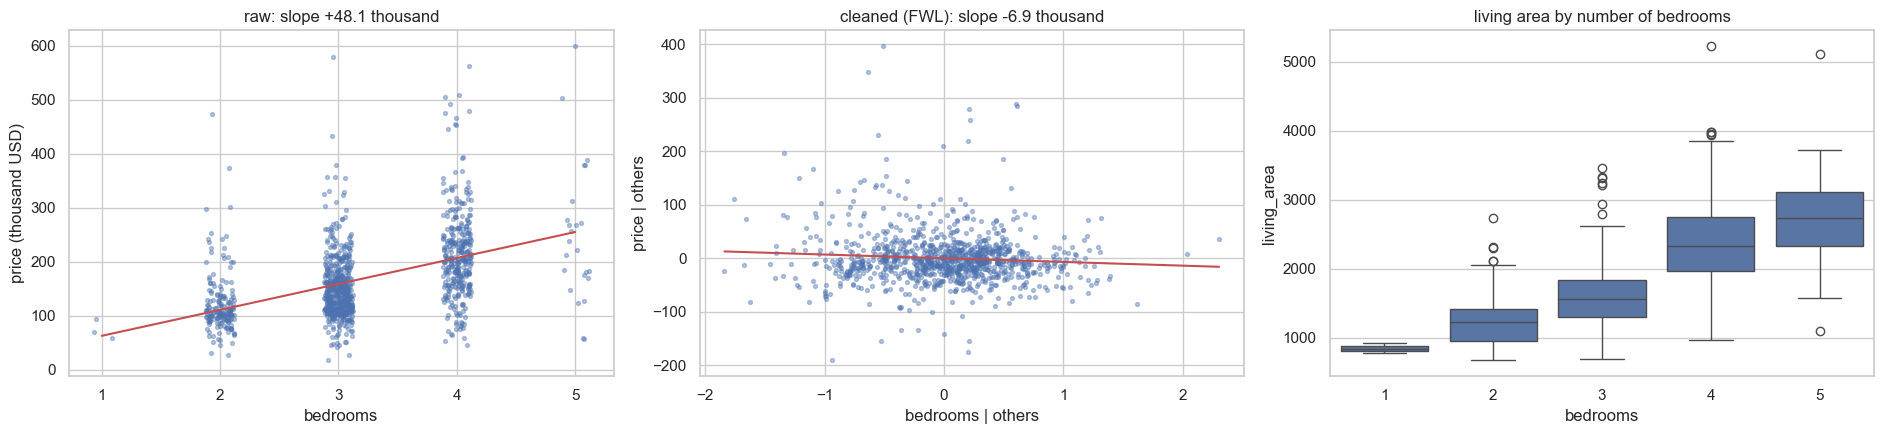

mean price (thousand USD) by area quartile and bedrooms:
bedrooms              1      2      3      4      5
living_area                                        
(671.999, 1339.0]  74.0  111.0  113.0  104.0  124.0
(1339.0, 1678.0]    NaN  123.0  135.0  128.0  147.0
(1678.0, 2217.5]    NaN  181.0  179.0  174.0   92.0
(2217.5, 5228.0]    NaN  221.0  253.0  248.0  277.0


In [9]:
j = 3
xb = X[:, j]
b_simple = my_ols(np.column_stack([np.ones(n), xb]), y)[0]
X_mj = np.delete(X, j, axis=1)
xb_t = my_ols(X_mj, xb)[2]
y_t = my_ols(X_mj, y)[2]
b_fwl = (xb_t @ y_t) / (xb_t @ xb_t)
R2_aux = 1 - xb_t @ xb_t / np.sum((xb - xb.mean()) ** 2)
print(f'simple slope {b_simple[1]:.0f}, multiple {beta[j]:.0f}, FWL {b_fwl:.0f};  R^2 aux = {R2_aux:.3f}, VIF = {1 / (1 - R2_aux):.2f}')

fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
ax[0].scatter(jit(xb, 0.12), y / 1000, s=8, alpha=0.4)
ax[0].plot([1, 5], (b_simple[0] + b_simple[1] * np.array([1, 5])) / 1000, 'r')
ax[0].set(xlabel='bedrooms', ylabel='price (thousand USD)', title=f'raw: slope {b_simple[1] / 1000:+.1f} thousand')
ax[1].scatter(xb_t, y_t / 1000, s=8, alpha=0.4)
g = np.array([xb_t.min(), xb_t.max()])
ax[1].plot(g, b_fwl * g / 1000, 'r')
ax[1].set(xlabel='bedrooms | others', ylabel='price | others', title=f'cleaned (FWL): slope {b_fwl / 1000:+.1f} thousand')
sns.boxplot(x=df['bedrooms'], y=df['living_area'], ax=ax[2]); ax[2].set_title('living area by number of bedrooms')
plt.tight_layout()
plt.show()
area_bins = pd.qcut(df['living_area'], 4)
print('mean price (thousand USD) by area quartile and bedrooms:')
print((df.groupby([area_bins, 'bedrooms'], observed=True)['price'].mean() / 1000).unstack().round(0))

- Simple slope +48 thousand USD per bedroom; in the model of Task 01 −6.9 thousand (standard error 2.8 thousand, so the negative sign is supported by the data, the size only roughly). FWL: the slope of $\mathbf{M}_{-j}\mathbf{y}$ on $\mathbf{M}_{-j}\mathbf{x}_j$ equals the multiple coefficient.
- $R^2$ of bedrooms on the other regressors 0.455: almost half of the variation of bedrooms is "living area and bathrooms". [beyond Lecture 5: the collinearity chapter will call $1/(1-R^2_j) = 1.83$ the variance inflation factor.]
- Boxplot: more bedrooms, larger house. Table: within the same area quartile, houses with **4 bedrooms are slightly cheaper than with 3** in all four quartiles, although they are larger within the quartile. Other cells (1 and 5 bedrooms) are too sparse to read.
- For an agent: buyers pay for floor area. Two houses of the same size, bathrooms, age and fireplace, one with an extra bedroom, sell on average for about 7 thousand USD *less*: the same area cut into smaller rooms.

## Task 05 - Dummy variables and the trap

In [10]:
no_fp = 1 - X[:, 5]
X5 = np.column_stack([X, no_fp])
names5 = names + ['no_fireplace']
fit5 = sm.OLS(y, X5).fit()
b5_qr = my_ols(X5, y)[0]
t_null = np.array([1, 0, 0, 0, 0, -1, -1.0])
print(f'rank {np.linalg.matrix_rank(X5)} of {X5.shape[1]};  X5 t = 0: {np.allclose(X5 @ t_null, 0)}')
est = lambda b: pd.Series({'living_area': b[1], 'bathrooms': b[2], 'bedrooms': b[3], 'age': b[4],
                           'b0 + b_fp': b[0] + b[5], 'b0 + b_nofp': b[0] + b[6], 'b_fp - b_nofp': b[5] - b[6]})
display(pd.DataFrame({'pinv (statsmodels)': est(fit5.params), 'pinv + 1e4 t': est(fit5.params + 1e4 * t_null),
                      'own QR, no pivoting': est(b5_qr), 'Task 01': est(np.r_[beta, 0])}))
print('own QR raw coefficients:', np.round(b5_qr[[0, 5, 6]], -10))

X6 = np.column_stack([X[:, 1:], no_fp])
fit6 = sm.OLS(y, X6).fit()
print(f'no intercept, both dummies: rank {np.linalg.matrix_rank(X6)} of {X6.shape[1]};  same fitted values: {np.allclose(fit6.fittedvalues, y_hat)}')
print(f'coef fireplace = b0 + b_fp: {fit6.params[4]:.1f} = {beta[0] + beta[5]:.1f};  coef no_fireplace = b0: {fit6.params[5]:.1f} = {beta[0]:.1f}')
print(f'R^2 statsmodels: {fit6.rsquared:.4f} (Task 01: {R2:.4f}); uncentred: {fit6.fittedvalues @ fit6.fittedvalues / (y @ y):.4f};'
      f'  k_constant = {fit6.model.k_constant}')

rank 6 of 7;  X5 t = 0: True


,pinv (statsmodels),pinv + 1e4 t,"own QR, no pivoting",Task 01
living_area,75.2903,75.2903,75.3095,75.2903
bathrooms,18853.5437,18853.5437,18838.0868,18853.5437
bedrooms,-6923.2895,-6923.2895,-6928.1486,-6923.2895
age,-142.8697,-142.8697,-142.4934,-142.8697
b0 + b_fp,23788.8640,23788.8640,23944.0000,23788.8640
b0 + b_nofp,16005.2394,16005.2394,16152.0000,16005.2394
b_fp - b_nofp,7783.6246,7783.6246,7792.0000,7783.6246


own QR raw coefficients: [ 3.94612e+16 -3.94612e+16 -3.94612e+16]
no intercept, both dummies: rank 6 of 6;  same fitted values: True
coef fireplace = b0 + b_fp: 23788.9 = 23788.9;  coef no_fireplace = b0: 16005.2 = 16005.2
R^2 statsmodels: 0.6016 (Task 01: 0.6016); uncentred: 0.9304;  k_constant = 1


**1.** Rank 6 of 7: $\mathbf{1} = \text{fireplace} + \text{no\_fireplace}$; null space spanned by $\mathbf{t} = (1, 0, 0, 0, 0, -1, -1)^T$; $\widehat{\boldsymbol{\beta}} + \lambda\mathbf{t}$ solves the normal equations for every $\lambda$.
- **Identified** (same for every solution): slopes of the numerical variables, $\beta_0 + \beta_{fp}$, $\beta_0 + \beta_{nofp}$, $\beta_{fp} - \beta_{nofp}$ (= the coefficient of Task 01). Equal for the pinv solution and for pinv + $10^4\mathbf{t}$.
- `statsmodels` (pinv): minimum-norm solution. Own QR without pivoting divides by a rounding error: $\pm 4\cdot 10^{16}$, and even the "identified" combinations are wrong (23 944 instead of 23 789). The exact garbage depends on rounding and may differ on another computer.
- R's `lm`: QR **with** pivoting, `NA` for the last aliased column (`no_fireplace`); the rest is the model of Task 01.

**2.** Without intercept, both dummies: rank 6 of 6, the same fitted values, because $\mathbf{1} \in \mathcal{M}(\mathbf{X})$ (sum of the dummies), so $\mathcal{M}$ and $\mathbf{H}$ are the same. Coefficients: no_fireplace $= \beta_0$, fireplace $= \beta_0 + \beta_{fp}$, slopes unchanged.

**3.** statsmodels reports the centered $R^2 = 0.602$, not the uncentred 0.930: it detects the implicit constant (`k_constant = 1`). What matters is $\mathbf{1} \in \mathcal{M}(\mathbf{X})$, not an explicit column of ones. R decides by the formula (`- 1`) and would report the uncentred value here.

## Task 06 - Leverage as a data check

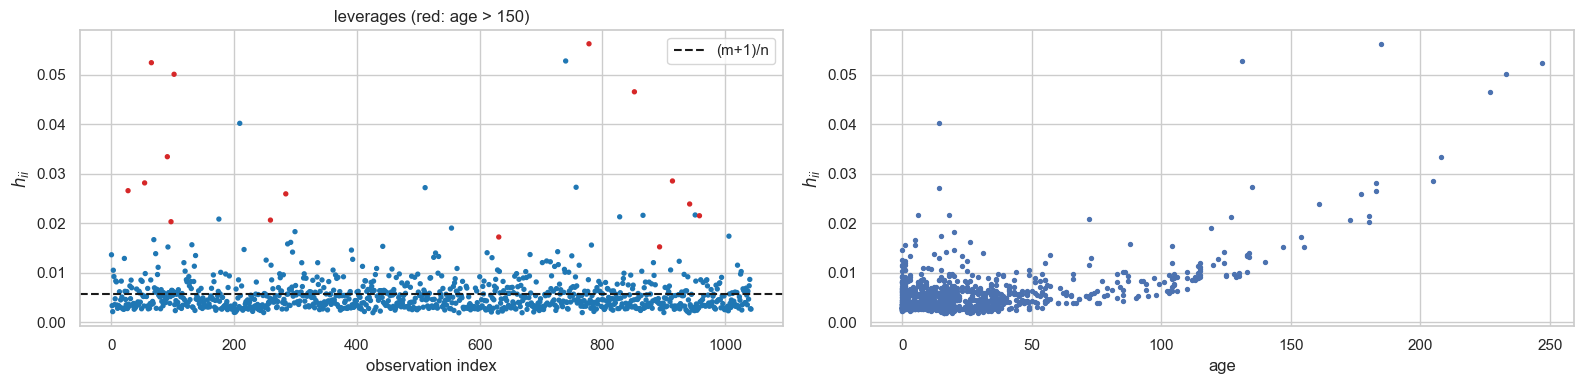

,price,living_area,bathrooms,bedrooms,age,fireplace,h_ii,ratio
778,88092.0,3944,1.0,4,185,True,0.0562,9.7712
740,599701.0,5114,4.5,5,131,True,0.0527,9.1677
65,226742.0,1989,2.0,3,247,True,0.0524,9.1074
102,59003.0,3285,2.0,5,233,False,0.0501,8.7012
852,75975.0,1300,2.0,3,227,True,0.0465,8.0859
209,562546.0,5228,4.0,4,14,True,0.0402,6.9798
91,185318.0,1500,1.5,4,208,True,0.0334,5.8080
914,139627.0,1980,1.0,4,205,False,0.0285,4.9559
54,157513.0,2164,2.0,3,183,True,0.0281,4.8883
757,139104.0,1760,3.0,4,135,False,0.0272,4.7358


age > 100: 71, > 150: 15, > 200: 5


,price,living_area,bathrooms,bedrooms,fireplaces,price_per_sqft
101-150,114650.2,1487.0,1.3,3.2,0.2,80.8
<= 100,171587.0,1835.7,2.0,3.2,0.6,94.7
> 150,119319.9,1940.1,1.5,3.2,0.6,65.6


,all,age <= 150,p all,p age <= 150
Intercept,16005.2394,12766.7526,3.0977e-02,8.8536e-02
living_area,75.2903,80.2523,2.4262e-69,2.6136e-75
bathrooms,18853.5437,17214.1726,4.6342e-07,4.8110e-06
bedrooms,-6923.2895,-8161.0617,1.2761e-02,3.4052e-03
age,-142.8697,-58.6359,3.4772e-03,3.2829e-01
fireplace,7783.6246,6984.2062,2.9433e-02,4.9940e-02


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].scatter(np.arange(n), hii, s=8, c=np.where(df['age'] > 150, 'tab:red', 'tab:blue'))
ax[0].axhline(p / n, color='k', ls='--', label='(m+1)/n'); ax[0].legend()
ax[0].set(xlabel='observation index', ylabel='$h_{ii}$', title='leverages (red: age > 150)')
ax[1].scatter(df['age'], hii, s=8); ax[1].set(xlabel='age', ylabel='$h_{ii}$')
plt.tight_layout()
plt.show()
top = np.argsort(hii)[::-1][:10]
display(df.loc[top, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']].assign(h_ii=hii[top], ratio=hii[top] / (p / n)))
print(f'age > 100: {(df["age"] > 100).sum()}, > 150: {(df["age"] > 150).sum()}, > 200: {(df["age"] > 200).sum()}')
grp = np.select([df['age'] > 150, df['age'] > 100], ['> 150', '101-150'], '<= 100')
display(df.groupby(grp)[['price', 'living_area', 'bathrooms', 'bedrooms', 'fireplaces', 'price_per_sqft']].mean().round(1))
keep = (df['age'] <= 150).to_numpy()
fit_all, fit_keep = sm.OLS(y, X).fit(), sm.OLS(y[keep], X[keep]).fit()
display(pd.DataFrame({'all': fit_all.params, 'age <= 150': fit_keep.params, 'p all': fit_all.pvalues, 'p age <= 150': fit_keep.pvalues}, index=names))

- Mean leverage $(m+1)/n = 0.0058$; the top ten have about 5–10 times more. Nine of them are older than 130 years (one also has 5114 sq ft); the tenth is the largest house (5228 sq ft, 14 years). The top one is the implausible 3944 sq ft house with 1 bathroom (Section 0).

**1.** Common feature: extreme `age`; 71 houses older than 100, 15 older than 150, 5 older than 200.
- 101–150 years: smaller, cheaper, fewer bathrooms and fireplaces: consistent with real old houses.
- Above 150 years: not smaller (mean 1940 sq ft), but the lowest price per sq ft (66 USD); several of the suspicious prices of Section 0.
- Plausibility depends on the region; ask how `age` is defined, check the year built, ask about the very cheap ones.

**2.** Without the 15 houses over 150 years: the age coefficient drops from −143 to −59 USD per year and loses significance ($p = 0.003 \to 0.33$); other coefficients move by up to about 20 % (bedrooms −6.9 → −8.2 thousand). The **linear** age effect stands on these 15 houses: report the decision.
- Removing points because of their $\mathbf{x}$ (implausible values) is legitimate; removing them because of their residuals or to change a result is not.

**3.** Leverage needs only $\mathbf{X}$: it measures how far $\mathbf{x}_i$ lies from the bulk of the regressors (for simple regression $h_{ii} = 1/n + (x_i - \overline{x})^2/S_{xx}$, Lecture 4). Typing errors in $\mathbf{X}$ create unusual combinations that stand out before $y$ is used, so the cleaning cannot be tuned to a desired result. Errors in $y$ need the residuals (Exercise 07).

## Task 07 - When the default fails: polynomials

In [12]:
a = df['living_area'].to_numpy(dtype=float)
a_std = (a - a.mean()) / a.std(ddof=1)
r2 = lambda yh: 1 - np.sum((y - yh) ** 2) / np.sum((y - y.mean()) ** 2)
rows = []
for d in range(1, 7):
    Xd, Zd = np.vander(a, d + 1, increasing=True), np.vander(a_std, d + 1, increasing=True)
    sv = np.linalg.svd(Xd, compute_uv=False)
    fd = sm.OLS(y, Xd).fit()
    rows.append({'d': d, 'kappa': np.linalg.cond(Xd), 'rank': np.linalg.matrix_rank(Xd), 'R2 default': fd.rsquared, 'df_model': fd.df_model,
                 'R2 qr': sm.OLS(y, Xd).fit(method='qr').rsquared, 'R2 my_ols': r2(my_ols(Xd, y)[1]),
                 'R2 standardized': sm.OLS(y, Zd).fit().rsquared, 'smallest s': sv[-1],
                 'cutoff statsmodels 1e-15 s1': 1e-15 * sv[0], 'tolerance matrix_rank': sv[0] * max(Xd.shape) * np.finfo(float).eps})
tab7 = pd.DataFrame(rows).set_index('d')
with pd.option_context('display.float_format', '{:.6g}'.format):
    display(tab7)

,kappa,rank,R2 default,df_model,R2 qr,R2 my_ols,R2 standardized,smallest s,cutoff statsmodels 1e-15 s1,tolerance matrix_rank
d,,,,,,,,,,
1,5660.94,2,0.573706,1,0.573706,0.573706,0.573706,11.0392,6.24923e-11,1.44727e-08
2,3.196e+07,3,0.581093,2,0.581093,0.581093,0.581093,4.78724,1.53e-07,3.54337e-05
3,1.91913e+11,4,0.581306,3,0.581306,0.581306,0.581306,2.39004,0.000458681,0.106227
4,1.53085e+15,4,0.578382,3,0.586026,0.586026,0.586026,1.06972,1.63758,379.252
5,1.52909e+19,4,0.563312,3,0.586131,0.586131,0.586131,0.44194,6757.68,1.56503e+06
6,9.47161e+22,4,0.508988,3,0.586177,0.586177,0.586177,0.326216,3.08979e+07,7.15572e+09


**1.** Nested models, $\mathcal{M}(\mathbf{X}_d) \subset \mathcal{M}(\mathbf{X}_{d+1})$: projection onto a larger subspace, SSE cannot grow, $R^2$ cannot fall. Violated by **`R2 default`** from $d = 4$ (0.5813 → 0.5784 → 0.5633 → 0.5090), with `df_model` stuck at 3.

**2.** The default (pseudoinverse via SVD) treats singular values below a cutoff as zero. statsmodels uses $10^{-15}\, s_1$; `np.linalg.matrix_rank` uses $s_1 \max(n,p)\,\varepsilon$, about 230 times more. With raw powers the columns differ by up to $10^{22}$, $s_1$ and both cutoffs are huge: from $d = 4$ the smallest singular values (1.07 vs. cutoff 1.6) fall under it. The rank is cut to 4, `df_model = 3`, and the fit is a projection onto a different 4-dimensional subspace, not even the cubic one. Not collinearity of the data, an artefact of scaling; the reported df and tests are wrong too. (At $\kappa \approx 10^{23}$ the computed smallest singular values are themselves inaccurate; the conclusion does not depend on it.)

**3.** QR projects with orthonormal $\mathbf{Q}$ and no thresholding, so $\widehat{\mathbf{y}}$ and $R^2$ stay right even when $\widehat{\boldsymbol{\beta}}$ is inaccurate. Standardizing is a regular reparametrization (same $\mathcal{M}$) with columns of comparable size: $\kappa$ drops from $10^{23}$ to about $3\cdot 10^3$. In practice: standardize or use orthogonal polynomials (R `poly()`), and check `df_model` and $\kappa$.

## Task 08 - Singular values and the variance of the estimates

In [13]:
Z = (X[:, 1:] - X[:, 1:].mean(axis=0)) / X[:, 1:].std(axis=0, ddof=1)
Xs = np.column_stack([np.ones(n), Z])
P_, S_, Qt_ = np.linalg.svd(Xs, full_matrices=False)
V_ = Qt_.T
fit_s = sm.OLS(y, Xs).fit()
print('singular values:', S_.round(3), f' kappa = {S_[0] / S_[-1]:.2f};  sqrt(n) = {np.sqrt(n):.3f}')
se_svd = np.sqrt(fit_s.scale * np.sum(V_ ** 2 / S_ ** 2, axis=1))
display(pd.DataFrame({'beta (per 1 sd)': fit_s.params, 'se SVD': se_svd, 'se statsmodels': fit_s.bse}, index=names))
share = (V_[3] ** 2 / S_ ** 2) / np.sum(V_[3] ** 2 / S_ ** 2)
k5 = int(np.argmax(share))
print('shares for bedrooms:', dict(zip([f'k={k + 1}' for k in range(p)], share.round(3))))
print(f'largest: k = {k5 + 1}, s_k = {S_[k5]:.2f}; direction q_k:', dict(zip(names, V_[:, k5].round(2))))
cleaned = my_ols(np.delete(Xs, 3, axis=1), Xs[:, 3])[2]
u5 = Xs @ V_[:, k5]
print(f'|cos| between X q_5 and the cleaned bedrooms M_-j x_j: {abs(u5 @ cleaned) / (np.linalg.norm(u5) * np.linalg.norm(cleaned)):.2f}')

singular values: [53.386 32.296 32.085 26.6   19.778 15.223]  kappa = 3.51;  sqrt(n) = 32.296


,beta (per 1 sd),se SVD,se statsmodels
Intercept,167778.3452,1512.9378,1512.9378
living_area,49822.7035,2621.4012,2621.4012
bathrooms,12276.2153,2419.8431,2419.8431
bedrooms,-5113.9934,2049.9463,2049.9463
age,-5014.6731,1712.1929,1712.1929
fireplace,3823.5951,1753.4147,1753.4147


shares for bedrooms: {'k=1': np.float64(0.038), 'k=2': np.float64(0.0), 'k=3': np.float64(0.142), 'k=4': np.float64(0.057), 'k=5': np.float64(0.596), 'k=6': np.float64(0.166)}
largest: k = 5, s_k = 19.78; direction q_k: {'Intercept': np.float64(-0.0), 'living_area': np.float64(0.26), 'bathrooms': np.float64(0.6), 'bedrooms': np.float64(-0.64), 'age': np.float64(0.37), 'fireplace': np.float64(-0.17)}
|cos| between X q_5 and the cleaned bedrooms M_-j x_j: 0.77


**1.** $\kappa(\mathbf{X}) = 3.5$ after standardization: no harmful collinearity (the columns are far from linearly dependent; [beyond Lecture 5] the collinearity chapter will give the rule of thumb of about 30). The second singular value equals $\sqrt{n}$: standardized columns are orthogonal to $\mathbf{1}$, so $\mathbf{1}/\sqrt{n}$ is a singular direction of its own.

**2.** $\mathbf{X}^T\mathbf{X} = \mathbf{Q}\mathbf{S}^2\mathbf{Q}^T \Rightarrow [(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$; the standard errors agree with `bse`.

**3.** For bedrooms, direction $k = 5$ ($s_5 = 19.8$, the second smallest) gives 60 % of the variance. $\mathbf{q}_5$ is a contrast: **more bedrooms with fewer bathrooms, smaller area and younger age** (signs opposite to bedrooms). Houses vary relatively little in this direction, so a coefficient that loads on it is estimated less precisely. Related to Task 04: $\mathbf{X}\mathbf{q}_5$ is close to, but not the same as, the cleaned bedrooms $\mathbf{M}_{-j}\mathbf{x}_j$ (|cos| = 0.77). The collinearity is mild: $s_5$ is only about 2.7 times smaller than $s_1$.

## Task 09 - Theorem 3.4 by simulation

,beta,mean of estimates,(mean - beta) / MC se,sd simulated,sd theory
Intercept,16005.2394,15882.8356,-0.7389,7266.0092,7408.7597
living_area,75.2903,75.2593,-0.3508,3.9373,3.9614
bathrooms,18853.5437,18877.7192,0.2909,3688.4198,3716.3423
bedrooms,-6923.2895,-6895.3393,0.4504,2743.2027,2775.2034
age,-142.8697,-141.2385,1.4955,49.3911,48.7810
fireplace,7783.6246,7791.6042,0.1000,3524.2739,3569.3952


sigma^2 = 2.3874e+09, mean s_n^2* = 2.3864e+09 (ratio 0.9996);  max |corr sim - theory| = 0.028
corr of estimates bedrooms/living_area: theory -0.475, simulated -0.462;  corr of the regressors 0.661, partial (given the other regressors) 0.475


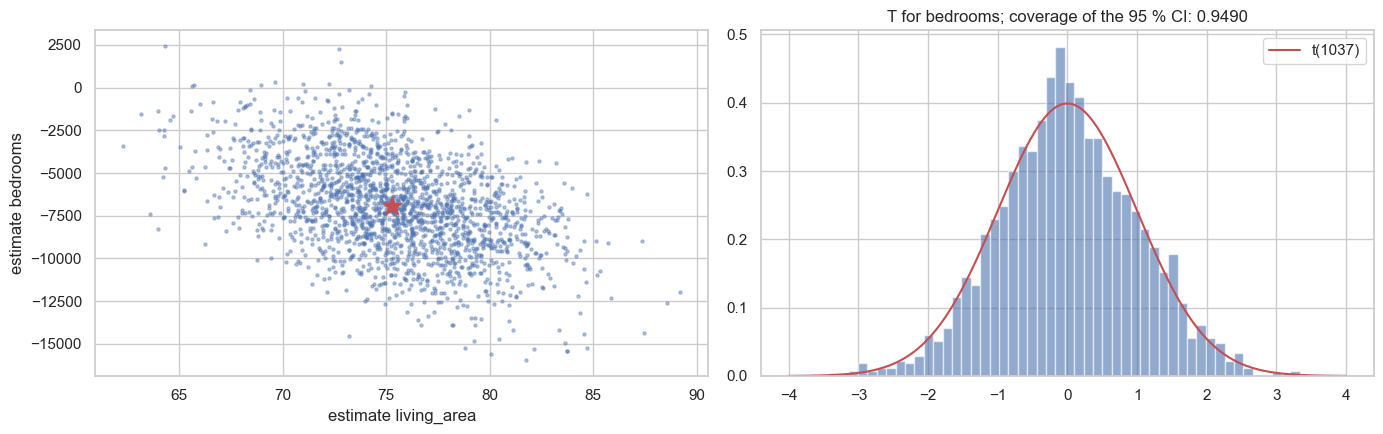

coverage of the 95 % CI for bedrooms: 0.9490 (Monte Carlo error +- 0.0097)


In [14]:
n_rep = 2000
sigma = np.sqrt(s2)
B = np.empty((n_rep, p)); S2 = np.empty(n_rep)
for r_ in range(n_rep):
    B[r_], _, _, S2[r_], _ = my_ols(X, X @ beta + rng.normal(0, sigma, n))
XtX_inv = np.linalg.inv(X.T @ X)
sd_th = sigma * np.sqrt(np.diag(XtX_inv))
corr_th = XtX_inv / np.sqrt(np.outer(np.diag(XtX_inv), np.diag(XtX_inv)))
display(pd.DataFrame({'beta': beta, 'mean of estimates': B.mean(axis=0), '(mean - beta) / MC se': (B.mean(axis=0) - beta) / (sd_th / np.sqrt(n_rep)),
                      'sd simulated': B.std(axis=0, ddof=1), 'sd theory': sd_th}, index=names))
print(f'sigma^2 = {s2:.4e}, mean s_n^2* = {S2.mean():.4e} (ratio {S2.mean() / s2:.4f});  max |corr sim - theory| = {np.abs(np.corrcoef(B, rowvar=False) - corr_th).max():.3f}')
X_rest = np.delete(X, [1, 3], axis=1)
part = np.corrcoef(my_ols(X_rest, X[:, 3])[2], my_ols(X_rest, X[:, 1])[2])[0, 1]
print(f'corr of estimates bedrooms/living_area: theory {corr_th[3, 1]:.3f}, simulated {np.corrcoef(B[:, 3], B[:, 1])[0, 1]:.3f};'
      f'  corr of the regressors {np.corrcoef(X[:, 3], X[:, 1])[0, 1]:.3f}, partial (given the other regressors) {part:.3f}')
T = (B[:, 3] - beta[3]) / np.sqrt(S2 * XtX_inv[3, 3])
tq = stats.t.ppf(0.975, n - p)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(B[:, 1], B[:, 3], s=5, alpha=0.4); ax[0].plot(beta[1], beta[3], 'r*', ms=14)
ax[0].set(xlabel='estimate living_area', ylabel='estimate bedrooms')
g = np.linspace(-4, 4, 300)
ax[1].hist(T, bins=50, density=True, alpha=0.6); ax[1].plot(g, stats.t.pdf(g, n - p), 'r', label=f't({n - p})'); ax[1].legend()
ax[1].set_title(f'T for bedrooms; coverage of the 95 % CI: {np.mean(np.abs(T) <= tq):.4f}')
plt.tight_layout()
plt.show()
print(f'coverage of the 95 % CI for bedrooms: {np.mean(np.abs(T) <= tq):.4f} (Monte Carlo error +- {2 * np.sqrt(0.05 * 0.95 / n_rep):.4f})')

**1.** Means of $\widehat{\boldsymbol{\beta}}^*$ within 1.5 Monte Carlo standard errors of $\boldsymbol{\beta}$; mean $s_n^{2*} / \sigma^2 = 0.9996$: unbiased (Theorem 3.4, points 1 and 3).

**2.** Simulated standard deviations within 2 % of $\sigma\sqrt{[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}$ (Monte Carlo error about 1.6 % with 2000 replications); correlations within 0.03.

**3.** Correlation of the estimates of bedrooms and living area: −0.46 simulated, −0.475 in theory, negative while the regressors are correlated +0.66. Both carry "size of the house": a sample that attributes more price to area attributes less to bedrooms; the cloud is an inclined ellipse (Task 04; with two regressors exactly $-r_{12}$, Exercise 05).
- [beyond Lecture 5] With more regressors the exact counterpart is the **partial** correlation of the two regressors given the others: +0.475 (printed), the correlation of the estimates with the opposite sign.

**4.** The histogram of $T$ follows $t(1037)$, practically $N(0,1)$; coverage of the 95 % interval 0.949, within the Monte Carlo error (Theorem 3.5).

## Task 10 - Fireplace: interaction and separate regressions

                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                      4.236e+04   7991.719      5.300      0.000    2.67e+04     5.8e+04
fireplace[T.True]             -3.825e+04   1.04e+04     -3.686      0.000   -5.86e+04   -1.79e+04
living_area                      59.6941      5.299     11.264      0.000      49.295      70.093
living_area:fireplace[T.True]    32.0624      6.108      5.249      0.000      20.077      44.048
{'no fireplace': (42356, np.float64(59.69)), 'fireplace': (4110, np.float64(91.76))}  lines cross at 1193 sq ft
H0: beta_ia = 0: t = 5.25, df = 1039, p = 1.9e-07


,interaction: coef,separate: coef
intercept no fp,42355.7506,42355.7506
slope no fp,59.6941,59.6941
intercept fp,4109.8000,4109.8000
slope fp,91.7566,91.7566


,s_n,"se slope (no fp, fp)"
interaction (pooled),49529.0621,"(5.299, 3.037)"
"separate, no fp",48376.5559,5.176
"separate, fp",50299.0636,3.085


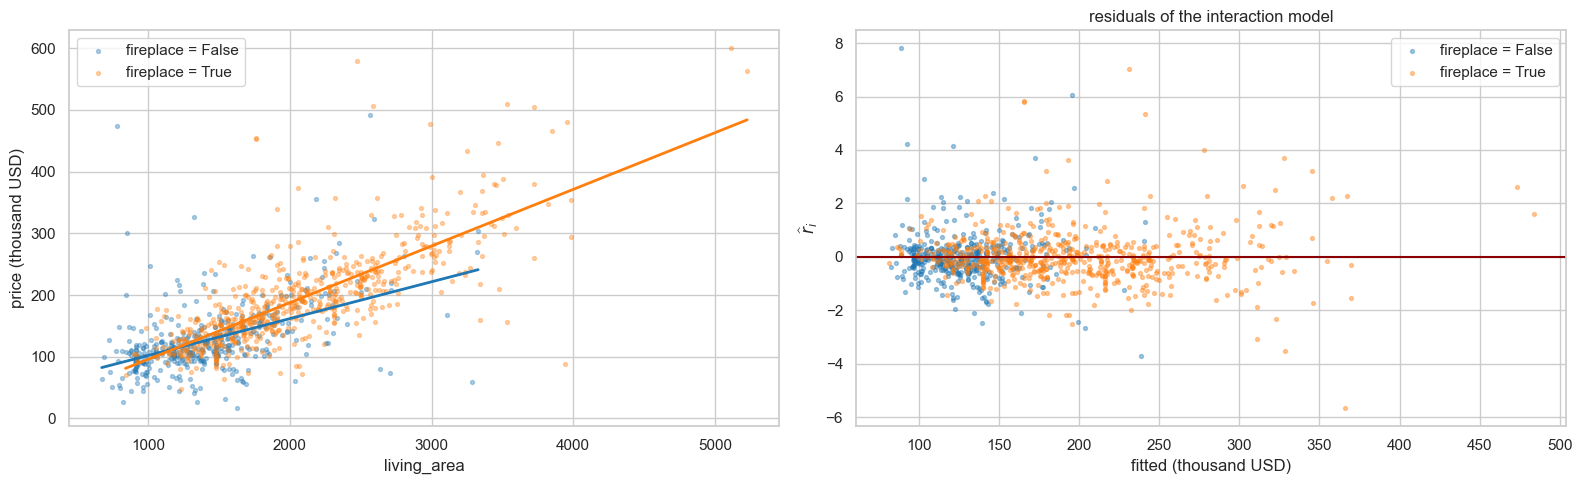

residual sd by group: {False: 48319.0, True: 50258.0}
residual sd by quartile of the fitted values: [43416.0, 35396.0, 53547.0, 60849.0]
living_area range: no fireplace [672, 3329] , fireplace [840, 5228]
only the common range of areas (n = 1011): interaction 29.0 USD/sq ft, t = 4.69, p = 3.1e-06


In [15]:
fit_int = smf.ols('price ~ living_area * fireplace', data=df).fit()          # R: lm(price ~ living_area * fireplace)
print(fit_int.summary().tables[1])
b_ = fit_int.params
lines = {'no fireplace': (b_['Intercept'], b_['living_area']),
         'fireplace': (b_['Intercept'] + b_['fireplace[T.True]'], b_['living_area'] + b_['living_area:fireplace[T.True]'])}
print({k: (round(v[0]), round(v[1], 2)) for k, v in lines.items()}, f' lines cross at {-b_["fireplace[T.True]"] / b_["living_area:fireplace[T.True]"]:.0f} sq ft')
ia = 'living_area:fireplace[T.True]'
print(f'H0: beta_ia = 0: t = {fit_int.tvalues[ia]:.2f}, df = {int(fit_int.df_resid)}, p = {fit_int.pvalues[ia]:.1e}')
sep = {fp: smf.ols('price ~ living_area', data=df[df['fireplace'] == fp]).fit() for fp in (False, True)}
cv = fit_int.cov_params()
se_slope_int = [fit_int.bse['living_area'], np.sqrt(cv.loc['living_area', 'living_area'] + cv.loc[ia, ia] + 2 * cv.loc['living_area', ia])]
display(pd.DataFrame({'interaction: coef': [*lines['no fireplace'], *lines['fireplace']],
                      'separate: coef': [*sep[False].params, *sep[True].params]},
                     index=['intercept no fp', 'slope no fp', 'intercept fp', 'slope fp']))
display(pd.DataFrame({'s_n': [np.sqrt(fit_int.scale), np.sqrt(sep[False].scale), np.sqrt(sep[True].scale)],
                      'se slope (no fp, fp)': [tuple(np.round(se_slope_int, 3)), round(sep[False].bse['living_area'], 3), round(sep[True].bse['living_area'], 3)]},
                     index=['interaction (pooled)', 'separate, no fp', 'separate, fp']))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for fp, col in [(False, 'tab:blue'), (True, 'tab:orange')]:
    sub = df[df['fireplace'] == fp]
    ax[0].scatter(sub['living_area'], sub['price'] / 1000, s=8, alpha=0.35, color=col, label=f'fireplace = {fp}')
    xs_ = np.linspace(sub['living_area'].min(), sub['living_area'].max(), 50)
    ax[0].plot(xs_, (lines['fireplace' if fp else 'no fireplace'][0] + lines['fireplace' if fp else 'no fireplace'][1] * xs_) / 1000, color=col, lw=2)
    sel = (df['fireplace'] == fp).to_numpy()
    ax[1].scatter(fit_int.fittedvalues[sel] / 1000, fit_int.get_influence().resid_studentized_internal[sel], s=8, alpha=0.4, color=col, label=f'fireplace = {fp}')
ax[0].set(xlabel='living_area', ylabel='price (thousand USD)'); ax[0].legend()
ax[1].axhline(0, color='darkred'); ax[1].legend()
ax[1].set(xlabel='fitted (thousand USD)', ylabel='$\\widehat{r}_i$', title='residuals of the interaction model')
plt.tight_layout()
plt.show()
print('residual sd by group:', fit_int.resid.groupby(df['fireplace']).std().round(0).to_dict())
print('residual sd by quartile of the fitted values:', fit_int.resid.groupby(pd.qcut(fit_int.fittedvalues, 4), observed=True).std().round(0).tolist())
print('living_area range: no fireplace', df.loc[~df['fireplace'], 'living_area'].agg(['min', 'max']).tolist(),
      ', fireplace', df.loc[df['fireplace'], 'living_area'].agg(['min', 'max']).tolist())
overlap = df['living_area'] <= df.loc[~df['fireplace'], 'living_area'].max()
fit_ov = smf.ols('price ~ living_area * fireplace', data=df[overlap]).fit()
print(f'only the common range of areas (n = {overlap.sum()}): interaction {fit_ov.params[ia]:.1f} USD/sq ft, t = {fit_ov.tvalues[ia]:.2f}, p = {fit_ov.pvalues[ia]:.1e}')

**1.** Columns $\mathbf{1}$, $f$ (fireplace), $a$ (`living_area`), $a\cdot f$. Without a fireplace $42\,356 + 59.7\,a$; with a fireplace $(\beta_0 + \beta_f) + (\beta_a + \beta_{af})a = 4\,110 + 91.8\,a$.
- $\beta_0$ (USD): price without fireplace at 0 sq ft (extrapolation); $\beta_f$ (USD): difference of the lines at 0 sq ft; $\beta_a$ (USD/sq ft): price per sq ft without fireplace; $\beta_{af}$ (USD/sq ft): additional price per sq ft with a fireplace. The lines cross near 1190 sq ft.

**2.** $H_0: \beta_{af} = 0$ vs. $H_1: \beta_{af} \ne 0$; $T = \widehat{\beta}_{af}/(s_n\sqrt{v_{af}}) = 5.25$, $t(n-4) = t(1039)$ under $H_0$ (Theorem 3.5), $p = 2\cdot 10^{-7}$: reject, houses with a fireplace have a higher price per sq ft **in this model**.

**3.** Separate regressions reproduce both lines exactly: $(1-f), a(1-f), f, af$ is a regular transformation of $\mathbf{1}, f, a, af$ (same $\mathcal{M}$); after sorting the rows by group the matrix is block diagonal and the normal equations split into the two simple regressions.

**4.** The blocks of $(\mathbf{X}^T\mathbf{X})^{-1}$ are the same, so the standard errors differ only through $s_n$: pooled 49 530 vs. 48 380 (no fireplace) and 50 300 (fireplace). The interaction model assumes **one $\sigma^2$ for both groups**.
- Check 1, group variances: residual standard deviations 48 and 50 thousand, practically equal; pooling is fine and gives one direct test of the slopes. Preferred here.
- Check 2, residuals against fitted values (key of Exercise 05, Section 5.4): a **funnel**, the residual standard deviation grows from about 35–43 thousand in the lower quartiles to 61 thousand in the top one. Not a difference *between* the groups but *within* them: $\sigma^2$ is not constant, so the $p$-value of the $t$-test is only approximate.
- Check 3, common range: houses without a fireplace end at 3329 sq ft, with a fireplace go up to 5228. Refit on houses up to 3329 sq ft (1011 of 1043): the interaction stays (29 USD/sq ft, $p = 3\cdot 10^{-6}$), so it is not produced by the largest houses alone.
- Conclusion within the course so far: the slopes differ in USD per sq ft; the test is approximate because of the funnel.

**[beyond Lecture 5]** The funnel suggests a transformation of the response. Exercise 05 previewed $\ln y$; transformations, Box–Cox, AIC, tests of constant variance (Breusch–Pagan) and robust standard errors (HC3) come later in the course (Exercise 08). The answer above does not need them; the cell below shows what they add.

In [16]:
fit_log = smf.ols('np.log(price) ~ living_area * fireplace', data=df).fit()
print(f'log(price) (previewed in Exercise 05, Section 5.4): interaction p = {fit_log.pvalues[ia]:.2f};  fireplace in the parallel log model:'
      f' {100 * (np.exp(smf.ols("np.log(price) ~ living_area + fireplace", data=df).fit().params["fireplace[T.True]"]) - 1):.1f} %')
print('HC3 (robust) p of the interaction in levels:', f"{smf.ols('price ~ living_area * fireplace', data=df).fit(cov_type='HC3').pvalues[ia]:.1e}")
# Box-Cox: profile likelihood of lambda in the interaction model
Xi = fit_int.model.exog
gm = np.exp(np.log(y).mean())
lams = np.round(np.arange(-0.5, 1.01, 0.05), 2)
sse = [np.sum((z - Xi @ np.linalg.lstsq(Xi, z, rcond=None)[0]) ** 2)
       for z in [(y ** L - 1) / (L * gm ** (L - 1)) if L != 0 else gm * np.log(y) for L in lams]]
lam_opt = lams[int(np.argmin(sse))]
df['price_bc'] = (y ** lam_opt - 1) / lam_opt
print(f'Box-Cox lambda (profile likelihood): {lam_opt}')
specs = {'price ~ area * fp': ('price ~ living_area * fireplace', 'level'),
         f'Box-Cox({lam_opt}) ~ area * fp': ('price_bc ~ living_area * fireplace', lam_opt),
         'log price ~ area + fp': ('np.log(price) ~ living_area + fireplace', 0),
         'log price ~ area * fp': ('np.log(price) ~ living_area * fireplace', 0),
         'log price ~ log area * fp': ('np.log(price) ~ np.log(living_area) * fireplace', 0)}
rows10 = {}
for k, (fm, L) in specs.items():
    ft = smf.ols(fm, data=df).fit()
    last = ft.model.exog_names[-1]
    jac = 0 if L == 'level' else -2 * (L - 1) * np.log(y).sum()        # AIC on the scale of price (Jacobian)
    rows10[k] = {'interaction p': ft.pvalues[last] if ':' in last else np.nan, 'AIC on the price scale': ft.aic + jac,
                 'Breusch-Pagan p': het_breuschpagan(ft.resid, ft.model.exog)[1]}
display(pd.DataFrame(rows10).T)
odd = (df['age'] > 150) | (df['price_per_sqft'] < 25) | (df['price_per_sqft'] > 250)
for k, fm in [('price, HC3', 'price ~ living_area * fireplace'), ('log price', 'np.log(price) ~ living_area * fireplace')]:
    ft = smf.ols(fm, data=df[~odd]).fit(cov_type='HC3' if 'HC3' in k else 'nonrobust')
    print(f'without {odd.sum()} suspicious houses, {k}: interaction p = {ft.pvalues.iloc[-1]:.3f}')
for fp in (False, True):
    print(f'elasticity log price ~ log area, fireplace = {fp}: {smf.ols("np.log(price) ~ np.log(living_area)", data=df[df["fireplace"] == fp]).fit().params.iloc[1]:.2f}')

log(price) (previewed in Exercise 05, Section 5.4): interaction p = 0.52;  fireplace in the parallel log model: 16.3 %
HC3 (robust) p of the interaction in levels: 6.8e-04
Box-Cox lambda (profile likelihood): 0.3


,interaction p,AIC on the price scale,Breusch-Pagan p
price ~ area * fp,1.8517e-07,25514.2149,7.6003e-05
Box-Cox(0.3) ~ area * fp,3.9788e-02,25262.4665,1.0590e-03
log price ~ area + fp,NaN,25320.7757,2.9487e-05
log price ~ area * fp,5.2115e-01,25322.3623,6.2605e-05
log price ~ log area * fp,1.9821e-07,25320.4274,7.8741e-05


without 21 suspicious houses, price, HC3: interaction p = 0.001
without 21 suspicious houses, log price: interaction p = 0.664
elasticity log price ~ log area, fireplace = False: 0.61
elasticity log price ~ log area, fireplace = True: 0.94


- Robust (HC3) errors and leaving out the 21 suspicious houses keep the interaction in USD significant.
- **But the conclusion depends on the scale of the price** (AIC on the price scale, comparable across transformations):
  - `log(price) ~ area * fp`: interaction $p = 0.52$; a fireplace goes with about +16 % of the price at any size;
  - `log(price) ~ log(area) * fp`: significant again (elasticity 0.94 with, 0.61 without fireplace); both log models fit equally (AIC ≈ 25 320), and log does not remove the funnel;
  - Box–Cox $\lambda \approx 0.3$ fits best (AIC 25 262): interaction borderline, $p = 0.04$.
- Houses with a fireplace are clearly more expensive; whether the *slope* differs is not settled by these data. "Price per sq ft differs" is a statement about one scale.

## Task 11 - Summary

- The column space, not the columns, determines the fit: units, centering, two dummies without intercept, interaction vs. separate regressions all give the same $\mathbf{H}$, $\widehat{\mathbf{y}}$, $R^2$; only $\widehat{\boldsymbol{\beta}}$ and its meaning change.
- FWL explained the bedroom paradox; the SVD showed which direction of the data limits its precision. `summary()` shows only a negative number.
- Rank deficiency: identified combinations vs. arbitrary coefficients; R's `NA`, statsmodels' minimum norm, garbage from QR without pivoting.
- Numerics: QR (with pivoting for rank-deficient matrices) or SVD with a sensible cutoff, on standardized regressors; check $\kappa$ and `df_model`: the default pinv silently cut the rank of the polynomial models.
- Data to report: 12 duplicated rows, ages above 150–200 years on which the linear age effect rests, prices per sq ft from 10 to 600 USD, implausible combinations (3944 sq ft with one bathroom); ask how `age` is defined.
- The fireplace interaction is significant in USD, also on the common range of areas, but the residuals form a funnel, so the $t$-test is approximate. [beyond Lecture 5: on other scales of the price the interaction disappears or becomes borderline, Task 10.]